# Model A: TF-IDF Logistic Regression (Constance Chen)

In [217]:
import sys
from pathlib import Path

import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

import pandas as pd
from sklearn.base import clone

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import zipfile


In [218]:
# locate shared project folder
project_dir = Path.cwd().resolve()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

sys.path.insert(0, str(project_dir))

# import data loading + splitting func
from data_utils import load_data, split_data

# kaggle zip
zip_path = project_dir / "data" / "cornell-tech-cs-5785-combined-2026-ai-vs-human-text.zip"

# load + split data
train, unlabeled, test = load_data(zip_path)
train_df, val_df = split_data(train)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)

Training: (8000, 3)
Validation: (2000, 3)


## Baseline model: Word TF-IDF + Logistic Regression

In [219]:
model_a = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True, # normalize words to lowercase
        ngram_range=(1, 2), # use individual words and consecutive word pairs
        min_df=2, # ignore terms appearing in fewer than 2 documents
        max_features=50000 # limit vocabulary to 50,000 features
    )),
    ("logreg", LogisticRegression(
        C=1.0, # regularization parameter
        max_iter=1000, # maximum optimization iterations
        random_state=42 # reproducibility
    ))
])

In [220]:
# train model a using 8k training samples
start_time = time.perf_counter()

model_a.fit(train_df["text"], train_df["label"])

train_time = time.perf_counter() - start_time

print(f"Train time: {train_time:.2f} seconds")

Train time: 4.43 seconds


## Model Evaluation

In [221]:
# predict probabilities for class 1 (AI-generated) on validation set
train_probs = model_a.predict_proba(train_df["text"])[:, 1]
val_probs = model_a.predict_proba(val_df["text"])[:, 1]

# calc AUROC scores
train_auc = roc_auc_score(train_df["label"], train_probs)
val_auc = roc_auc_score(val_df["label"], val_probs)

print(f"Train AUROC: {train_auc:.4f}")
print(f"Validation AUROC: {val_auc:.4f}")

Train AUROC: 0.9850
Validation AUROC: 0.9192


## Regularization Comparison

Compare Logistic Regression with no regularization, L1, and L2 regularization using the same baseline TF-IDF features and
training/validation split.
For L1 and L2, we initially use C=1.0 to compare penalty types.

In [222]:
# reuse TF-IDF features from fitted baseline model
# vectorizer was fitted on training data only
X_train_reg = model_a.named_steps["tfidf"].transform(train_df["text"])
X_val_reg = model_a.named_steps["tfidf"].transform(val_df["text"])

y_train = train_df["label"]
y_val = val_df["label"]

# compare three regularization approaches
reg_models = {
    "None": LogisticRegression(
        penalty=None,
        max_iter=1000,
        random_state=42
    ),
    "L1": LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=1.0,
        max_iter=1000,
        random_state=42
    ),
    "L2": LogisticRegression(
        penalty="l2",
        C=1.0,
        max_iter=1000,
        random_state=42
    )
}

reg_results = []

for name, model in reg_models.items():
    start_time = time.perf_counter()

    model.fit(X_train_reg, y_train)

    elapsed = time.perf_counter() - start_time

    # evaluate on training and validation sets
    train_probs_reg = model.predict_proba(X_train_reg)[:, 1]
    val_probs_reg = model.predict_proba(X_val_reg)[:, 1]

    reg_results.append({
        "Regularization": name,
        "Train AUROC": roc_auc_score(y_train, train_probs_reg),
        "Validation AUROC": roc_auc_score(y_val, val_probs_reg),
        "Time (s)": elapsed
    })

reg_results_df = pd.DataFrame(reg_results)
print(reg_results_df.round(4).to_string(index=False))

Regularization  Train AUROC  Validation AUROC  Time (s)
          None       0.9999            0.9290    0.2463
            L1       0.9173            0.8953    0.3537
            L2       0.9850            0.9192    0.2161


### Regularization Strength Comparison

We compare L1 and L2 regularization across different values of C, using the same TF-IDF features and fixed validation split.
We also include the unregularized model as a reference.
Smaller C values correspond to stronger regularization.

In [223]:
# test different regularization strengths
c_values = [0.01, 0.1, 1, 10, 100]

grid_results = []

for penalty in ["l1", "l2"]:
    for c in c_values:

        # L1 requires a compatible solver
        solver = "liblinear" if penalty == "l1" else "lbfgs"

        model = LogisticRegression(
            penalty=penalty,
            solver=solver,
            C=c,
            max_iter=1000,
            random_state=42
        )

        # train on the same TF-IDF training features
        model.fit(X_train_reg, y_train)

        # evaluate training and validation AUROC
        train_probs = model.predict_proba(X_train_reg)[:, 1]
        val_probs = model.predict_proba(X_val_reg)[:, 1]

        grid_results.append({
            "Penalty": penalty.upper(),
            "C": c,
            "Train AUROC": roc_auc_score(y_train, train_probs),
            "Validation AUROC": roc_auc_score(y_val, val_probs)
        })

grid_df = pd.DataFrame(grid_results)

print(grid_df.round(4).to_string(index=False))

Penalty      C  Train AUROC  Validation AUROC
     L1   0.01       0.5000            0.5000
     L1   0.10       0.6721            0.6563
     L1   1.00       0.9173            0.8953
     L1  10.00       1.0000            0.9214
     L1 100.00       1.0000            0.9188
     L2   0.01       0.8433            0.8006
     L2   0.10       0.9089            0.8618
     L2   1.00       0.9850            0.9192
     L2  10.00       1.0000            0.9308
     L2 100.00       1.0000            0.9291


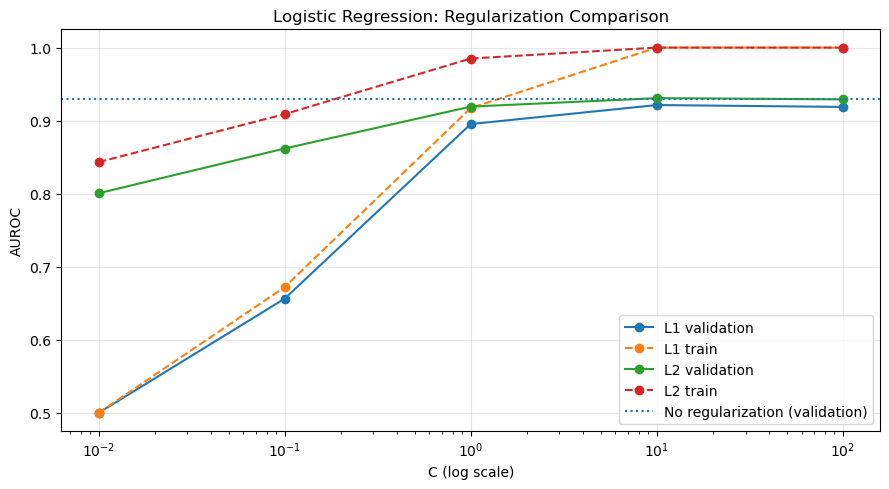

In [224]:

plt.figure(figsize=(9, 5))

# plot L1 and L2 training and validation AUROC
for penalty in ["L1", "L2"]:
    subset = grid_df[grid_df["Penalty"] == penalty]

    plt.plot(
        subset["C"],
        subset["Validation AUROC"],
        marker="o",
        label=f"{penalty} validation"
    )

    plt.plot(
        subset["C"],
        subset["Train AUROC"],
        marker="o",
        linestyle="--",
        label=f"{penalty} train"
    )

# unregularized model does not depend on C
no_reg_auc = reg_results_df.loc[
    reg_results_df["Regularization"] == "None",
    "Validation AUROC"
].iloc[0]

plt.axhline(
    y=no_reg_auc,
    linestyle=":",
    label="No regularization (validation)"
)

plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("AUROC")
plt.title("Logistic Regression: Regularization Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [225]:

# select the best C for each regularization type
best_reg = grid_df.loc[
    grid_df.groupby("Penalty")["Validation AUROC"].idxmax()
].copy()

# add the unregularized model for comparison
no_reg = pd.DataFrame([{
    "Penalty": "None",
    "C": float("nan"),
    "Train AUROC": reg_results_df.loc[
        reg_results_df["Regularization"] == "None",
        "Train AUROC"
    ].iloc[0],
    "Validation AUROC": reg_results_df.loc[
        reg_results_df["Regularization"] == "None",
        "Validation AUROC"
    ].iloc[0]
}])

reg_summary = pd.concat([no_reg, best_reg], ignore_index=True)
print(reg_summary.round(4).to_string(index=False))


Penalty    C  Train AUROC  Validation AUROC
   None  NaN       0.9999            0.9290
     L1 10.0       1.0000            0.9214
     L2 10.0       1.0000            0.9308


In [226]:

# compare how many TF-IDF features retain nonzero weights
for name in ["L1", "L2"]:
    coefficients = reg_models[name].coef_[0]
    nonzero = (abs(coefficients) > 1e-8).sum()

    print(f"{name}: {nonzero} / {len(coefficients)} nonzero coefficients")

L1: 253 / 50000 nonzero coefficients
L2: 50000 / 50000 nonzero coefficients



### Regularization Results

L2 regularization achieved the highest validation AUROC (0.9308) at C=10, compared with 0.9214 for L1 and 0.9290 without regularization. Stronger regularization generally reduced performance, particularly for L1 at smaller C values.

Although training AUROC approached 1.0 for larger C values, validation AUROC eventually plateaued or decreased, suggesting some overfitting. We therefore continued with L2 regularization at C=10 for subsequent TF-IDF hyperparameter tuning.

At C=1, L1 retained only 253 nonzero coefficients out of 50,000, compared with all 50,000 for L2. This demonstrates how L1 encourages sparsity and effectively performs feature selection.

## Hyperparameter Tuning

In [227]:
# test different regularization strengths
c_values = [0.01, 0.1, 1.0, 10.0, 100.0]
results = []

for c in c_values:
    # create fresh copy of baseline model
    model = clone(model_a)
    model.set_params(logreg__C=c)

    # train model and measure runtime
    start_time = time.perf_counter()
    model.fit(train_df["text"], train_df["label"])
    elapsed = time.perf_counter() - start_time

    # predict AI probabilities
    train_probs = model.predict_proba(train_df["text"])[:, 1]
    val_probs = model.predict_proba(val_df["text"])[:, 1]

    # calc AUROC
    train_auc = roc_auc_score(train_df["label"], train_probs)
    val_auc = roc_auc_score(val_df["label"], val_probs)

    results.append({
        "C": c,
        "Train AUROC": train_auc,
        "Val AUROC": val_auc,
        "Train time (s)": elapsed
    })

# compare results, ranked by validation AUROC
results_df = pd.DataFrame(results)
results_df.sort_values("Val AUROC", ascending=False)

,C,Train AUROC,Val AUROC,Train time (s)
3,10.00,1.000000,0.930814,4.115950
4,100.00,1.000000,0.929148,4.193076
2,1.00,0.985028,0.919218,4.066679
1,0.10,0.908932,0.861848,4.095548
0,0.01,0.843267,0.800595,4.151910


### TF-IDF N-gram Tuning

In [228]:
# test different word n-gram ranges
# keep C=10 and other tf-idf settings fixed
ngram_values = [(1, 1), (1, 2), (1, 3)]
ngram_results = []

for ngram in ngram_values:
    # create fresh copy of baseline model
    model = clone(model_a)

    # change n-gram range and use best C from prev experiment
    model.set_params(
        tfidf__ngram_range=ngram,
        logreg__C=10.0
    )

    # train model and measure runtime
    start_time = time.perf_counter()
    model.fit(train_df["text"], train_df["label"])
    elapsed = time.perf_counter() - start_time

    # predict AI probabilities
    train_probs = model.predict_proba(train_df["text"])[:, 1]
    val_probs = model.predict_proba(val_df["text"])[:, 1]

    # calc AUROC
    train_auc = roc_auc_score(train_df["label"], train_probs)
    val_auc = roc_auc_score(val_df["label"], val_probs)

    # store results for comparison
    ngram_results.append({
        "N-gram range": str(ngram),
        "Train AUROC": train_auc,
        "Val AUROC": val_auc,
        "Train time (s)": elapsed
    })

    print(f"Finished {ngram}: Val AUROC = {val_auc:.4f}")

# compare configurations, ranked by validation AUROC
ngram_df = pd.DataFrame(ngram_results)
ngram_df.sort_values("Val AUROC", ascending=False)


Finished (1, 1): Val AUROC = 0.9049
Finished (1, 2): Val AUROC = 0.9308
Finished (1, 3): Val AUROC = 0.9342


,N-gram range,Train AUROC,Val AUROC,Train time (s)
2,"(1, 3)",0.999997,0.934169,9.260962
1,"(1, 2)",1.000000,0.930814,4.246221
0,"(1, 1)",0.999696,0.904854,0.977597


### TF-IDF min_df Tuning

In [229]:
# test different minimum document frequencies
# keep C=10 and ngram_range=(1,3) fixed
min_df_values = [2, 3, 5]
min_df_results = []

for min_df in min_df_values:
    # create fresh copy of baseline model
    model = clone(model_a)

    # use best settings from prev experiments
    model.set_params(
        tfidf__ngram_range=(1, 3),
        tfidf__min_df=min_df,
        logreg__C=10.0
    )

    # train model and measure runtime
    start_time = time.perf_counter()
    model.fit(train_df["text"], train_df["label"])
    elapsed = time.perf_counter() - start_time

    # predict AI probabilities
    train_probs = model.predict_proba(train_df["text"])[:, 1]
    val_probs = model.predict_proba(val_df["text"])[:, 1]

    # calc AUROC
    train_auc = roc_auc_score(train_df["label"], train_probs)
    val_auc = roc_auc_score(val_df["label"], val_probs)

    # store results
    min_df_results.append({
        "min_df": min_df,
        "Train AUROC": train_auc,
        "Val AUROC": val_auc,
        "Train time (s)": elapsed
    })

    print(f"Finished min_df={min_df}: Val AUROC = {val_auc:.4f}")

# compare results by validation AUROC
min_df_df = pd.DataFrame(min_df_results)
min_df_df.sort_values("Val AUROC", ascending=False)


Finished min_df=2: Val AUROC = 0.9342
Finished min_df=3: Val AUROC = 0.9354
Finished min_df=5: Val AUROC = 0.9357


,min_df,Train AUROC,Val AUROC,Train time (s)
2,5,0.999998,0.935697,9.152038
1,3,0.999999,0.935440,9.213632
0,2,0.999997,0.934169,9.447906


## Kaggle Submission: Tuned logistic regression


Train the selected model on all 10,000 labeled examples and
generate predicted probabilities for the 3,000 test examples.

In [230]:
# recreate best tuned LR model
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 3),
        min_df=5,
        max_features=50000
    )),
    ("logreg", LogisticRegression(
        C=10.0,
        max_iter=1000,
        random_state=42
    ))
])

# train on all 10,000 labeled ex
final_model.fit(train["text"], train["label"])

# predict probability of AI-generated text for Kaggle test data
test_probs = final_model.predict_proba(test["text"])[:, 1]

print(f"Training examples: {len(train)}")
print(f"Test predictions: {len(test_probs)}")


Training examples: 10000
Test predictions: 3000


In [231]:
# load kaggle's sample submission to match the expected format
with zipfile.ZipFile(zip_path) as z:
    sample_file = next(
        name for name in z.namelist()
        if name.endswith("sample_submission.csv")
        and not name.startswith("__MACOSX/")
    )
    submission = pd.read_csv(z.open(sample_file))

# identify prediction column
prediction_cols = [col for col in submission.columns if col != "id"]
assert len(prediction_cols) == 1
prediction_col = prediction_cols[0]

# match predicted probabilities to correct test IDs
prob_by_id = pd.Series(test_probs, index=test["id"])
submission[prediction_col] = submission["id"].map(prob_by_id)

# verify submission before saving
assert len(submission) == len(test)
assert submission[prediction_col].notna().all()
assert submission[prediction_col].between(0, 1).all()

# save submission file locally
output_path = project_dir / "submission.csv"
submission.to_csv(output_path, index=False)

print(f"Saved to: {output_path}")
print(submission.head())


Saved to: /Users/constancechen/Downloads/human-or-ai-submissions/submissions/group-38/submission.csv
      id     label
0  13001  0.964108
1  13002  0.055307
2  13003  0.489003
3  13004  0.023283
4  13005  0.966821
